# 10 — Apakah kata pada header membantu pengenalan dokumen?
Ensemble visual terakhir memperoleh akurasi validasi 88,4754%. Skor leaderboard terakhir yang dilaporkan, 0,88289, berasal dari ensemble ConvNeXt tahap 08. Eksperimen ini menguji satu hipotesis baru. Kata pada bagian atas halaman dapat membedakan dokumen yang tata letaknya mirip, misalnya form dan kuesioner.

In [1]:
from pathlib import Path
import hashlib, json, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'scripts').is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RUN = ROOT / 'reports/ocr_header'
result = json.loads((RUN / 'result.json').read_text())
display(pd.read_json(ROOT / 'reports/leaderboard_history.json')[['run_name','score']])
display(pd.read_csv(ROOT / 'reports/shift_selection/classification_report.csv', index_col=0).iloc[:16].sort_values('f1-score').head())

,run_name,score
0,baseline_cnn,0.67294
1,efficientnet_improved,0.85236
2,highres_selection,0.86491
3,convnext_selection,0.88289


,precision,recall,f1-score,support
scientific_report,0.755396,0.770171,0.762712,409.0
presentation,0.741093,0.789873,0.764706,395.0
form,0.750630,0.798928,0.774026,373.0
questionnaire,0.872679,0.856771,0.864652,384.0
budget,0.880952,0.856041,0.868318,389.0


## Ekstraksi dan pemeriksaan teks
Windows OCR membaca 45% bagian atas TIFF asli. Setiap teks dikaitkan dengan ID untuk pemeriksaan urutan. Classifier menerima n-gram kata dan karakter dari teks hasil pembacaan. Deretan digit dinormalisasi. Header kosong mengandalkan model visual. Tabel berikut mengukur jumlah kata yang terbaca dan perubahan akurasi menurut banyaknya kata pada halaman validasi.

In [2]:
val = pd.read_csv(RUN / 'validation_predictions.csv')
val['jumlah_kata'] = pd.cut(val.ocr_words, [-1,0,11,float('inf')], labels=['0', '1–11','12+'])
val['visual_benar'] = val.old_prediction.eq(val.label)
val['gabungan_benar'] = val.prediction.eq(val.label)
display(val.groupby('jumlah_kata', observed=True).agg(halaman=('id','size'), visual=('visual_benar','mean'), gabungan=('gabungan_benar','mean')))
display(val.groupby('class_name').ocr_words.median().sort_values().to_frame('median_kata'))

,halaman,visual,gabungan
jumlah_kata,,,
0,1305,0.880460,0.880460
1–11,980,0.854082,0.863265
12+,4110,0.893431,0.906813


,median_kata
class_name,
file_folder,0.0
handwritten,0.0
advertisement,3.0
budget,13.0
presentation,15.0
invoice,21.0
form,24.0
scientific_report,25.0
specification,36.0


## Training dan pembandingan
Kosakata TF-IDF dipelajari hanya dari training split. PyTorch EmbeddingBag menggabungkan embedding tiap n-gram berbobot TF-IDF, kemudian classifier memprediksi 16 kelas. Model dilatih selama 12 epoch tetap. Pada gabungan, bobot OCR adalah 0,38 × min(jumlah kata / 12, 1). Bobot sisanya diberikan kepada ensemble visual tahap 09.

{'run_name': 'ocr_header',
 'reference': 'shift_selection',
 'language': 'en-US',
 'header_fraction': 0.45,
 'scale': 1.35,
 'workers': 4,
 'chunk_size': 384,
 'max_word_features': 40000,
 'max_char_features': 40000,
 'hidden': 128,
 'epochs': 12,
 'batch_size': 256,
 'learning_rate': 0.002,
 'seed': 42,
 'ocr_weight': 0.38,
 'min_words_for_full_weight': 12,
 'bootstrap_replicates': 2000,
 'acceptance': 'higher accuracy and macro-F1, with positive lower 95% paired bootstrap gain by exact-pixel group'}

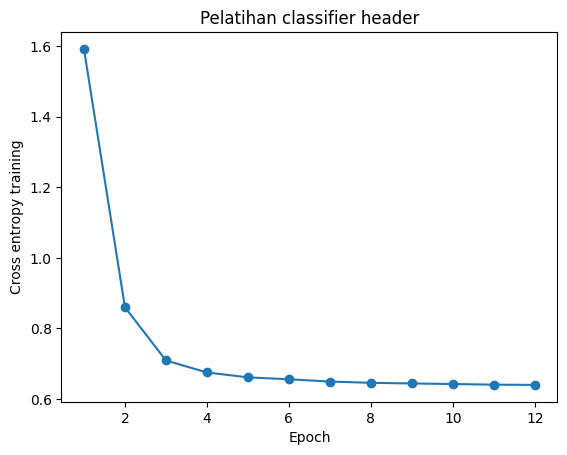

,model,accuracy,macro_f1
0,vision,0.884754,0.884134
1,ocr,0.648475,0.649989
2,vision_ocr,0.894762,0.893943


,class_name,old_f1,new_f1,delta_f1
13,scientific_publication,0.924731,0.913349,-0.011382
9,news_article,0.904824,0.897368,-0.007456
5,handwritten,0.944882,0.945701,0.000819
3,file_folder,0.922374,0.924658,0.002283
8,memo,0.927250,0.931540,0.004290
0,advertisement,0.900966,0.905569,0.004603
2,email,0.972405,0.977661,0.005256
7,letter,0.894526,0.904762,0.010236
1,budget,0.868318,0.880309,0.011991
14,scientific_report,0.762712,0.776819,0.014107


In [3]:
display(result['config'])
history = pd.read_csv(RUN / 'history.csv')
ax = history.plot(x='epoch',y='training_loss',marker='o',legend=False)
ax.set(xlabel='Epoch', ylabel='Cross entropy training', title='Pelatihan classifier header')
plt.show()
display(pd.read_csv(RUN / 'comparison.csv'))
display(pd.read_csv(RUN / 'class_comparison.csv').sort_values('delta_f1'))

## Keputusan dan batas evaluasi
Kandidat direkomendasikan jika akurasi dan macro-F1 meningkat sekaligus batas bawah interval bootstrap berpasangan 95% untuk kenaikan akurasi positif. Grup dibentuk dengan hash piksel agar gambar yang identik tetap bersama dalam sampling. Holdout ini telah dipakai untuk pemilihan model visual, sehingga hasil independen tetap memerlukan evaluasi kompetisi.

In [4]:
print('Lolos kriteria:', result['accepted'])
print('Interval perubahan akurasi (poin persentase):', [round(100*x,3) for x in result['paired_interval_95']])
print('Kesalahan diperbaiki:', result['corrected_errors'], 'Kesalahan baru:', result['new_errors'])
from scripts.preprocess import read_metadata, data_directory
from scripts.predict import validate_submission
_, test, sample = read_metadata(data_directory())
output = ROOT / result['submission']
submission = pd.read_csv(output)
validate_submission(submission, sample)
assert len(submission) == len(test) == result['test_rows']
assert hashlib.sha256(output.read_bytes()).hexdigest() == result['submission_sha256']
print(output.name, len(submission))
display(submission.head())

Lolos kriteria: True
Interval perubahan akurasi (poin persentase): [0.624, 1.385]
Kesalahan diperbaiki: 113 Kesalahan baru: 49


submission_ocr_header.csv 7994


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,6
3,test_00004,4
4,test_00005,13
